# Hindcast pipeline 2016 / 2017 / 2018 extent maps for Region 5

## Setup

In [1]:
import sys
import time
from pathlib import Path

import ee

sys.path.insert(0, "../../")

PROJECT = "irp-zu"

try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)

from mangrove_mapper import MangroveMapper

mm = MangroveMapper(project_name=PROJECT)
mm.config

{'default_aoi': [[-59.38308424806478, 8.054416523553055],
  [-58.884720106527595, 7.670222740307287],
  [-58.6066393915342, 7.3742767194813394],
  [-58.49646429770003, 6.993420918568921],
  [-57.771841640151585, 6.503265198524917],
  [-57.65508973640652, 6.412177452976993],
  [-57.568594569839085, 6.28012794549925],
  [-57.44877778487628, 6.245078372130237],
  [-57.23569020160864, 6.087540882000849],
  [-57.125826920358634, 5.866277255134532],
  [-57.11987172043847, 6.118209943117061],
  [-57.44671498215722, 6.410339167612445],
  [-58.10040150559472, 6.917750154191127],
  [-58.33111439621972, 7.168528757883949],
  [-58.63323841965722, 7.696886561702809],
  [-59.10290394700097, 8.132152633198771],
  [-59.69616566575097, 8.394445875718194],
  [-59.99279652512597, 8.549292721463692],
  [-59.53002638673666, 8.152306216451324]],
 'validation': {'pomeroon_river_aoi': [[-58.793201027447836,
    7.641999643312983],
   [-58.786311616793554, 7.633424575768573],
   [-58.77487394309828, 7.62119121

In [2]:
import numpy as np
import pandas as pd
import rasterio

from mangrove_mapper.inference import extent_tile, mosaic, predict_tile
from mangrove_mapper.models import MangroveClassifier
from mangrove_mapper.sensors import ALOSPalsar, Landsat8, Sentinel1, Sentinel2
from mangrove_mapper.utils.fusion import concat_sensors

REBUILD = False
 # Top of Atmosphere is used since Surface Reflectance, which is typically used for vegetation studies, is unreliable for this study window
S2_LEVEL = "TOA"
SFX = f"-{S2_LEVEL.lower()}"

# Sentinel-1 over this AOI is ASCENDING since descending is missing.
S1_ORBITS = ("ASCENDING",)

DATA = Path("../../data")
DATA.mkdir(parents=True, exist_ok=True)
TRAINED = Path("../../trained_models")
TRAINED.mkdir(parents=True, exist_ok=True)
HINDCAST = DATA / "hindcast"
HINDCAST.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:32621"
SCALE = 10
TILE = 512
THRESHOLD = 0.50
DRIVE_FOLDER = "MangroveMapper_ML_Exports"
TAG=50

# Retraining on TOA
MODEL_NAME = f"xgb_6k_gmw_full_fusion{SFX}-asc"
MODEL_PATH = TRAINED / f"{MODEL_NAME}.json"
TRAIN_CSV = DATA / f"training_data_coastwide{SFX}-asc.csv"
TRAIN_YEAR = 2020  

WINDOWS = {
    2016: ("2016-01-01", "2016-12-31"),
    2017: ("2017-01-01", "2017-12-31"),
    2018: ("2018-01-01", "2018-12-31"),
}

mc = MangroveClassifier()

In [3]:
# Region 5 hindcast AOI
AOI_COORDS = mm.config["hindcast"]["region_five_aoi"]

AOI = ee.Geometry.Polygon([AOI_COORDS])
CRS_TRANSFORM = mm.pinned_transform(crs=CRS, scale=SCALE)

## 1. Is there imagery for these years?

Might be a minute wait or two since this server side GEE call looks through all years and collections for the hindcast

In [4]:
COLLECTIONS = {
    "S2 TOA  (S2_HARMONIZED)":    "COPERNICUS/S2_HARMONIZED",
    "S2 SR   (S2_SR_HARMONIZED)": "COPERNICUS/S2_SR_HARMONIZED",
    "L8      (LC08/C02/T1_L2)":   "LANDSAT/LC08/C02/T1_L2",
    "ALOS    (PALSAR/YEARLY)":    "JAXA/ALOS/PALSAR/YEARLY/SAR_EPOCH",
}
S1_ID = "COPERNICUS/S1_GRD_FLOAT"

check_years = list(WINDOWS) + [2020]     

def _count(cid, start, end):
    return ee.ImageCollection(cid).filterBounds(AOI).filterDate(start, end).size().getInfo()

def _s1(start, end, orbit):
    c = (ee.ImageCollection(S1_ID).filterBounds(AOI).filterDate(start, end)
         .filter(ee.Filter.eq("instrumentMode", "IW"))
         .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
         .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    return c.filter(ee.Filter.eq("orbitProperties_pass", orbit)).size().getInfo()

rows = {}
for y in check_years:
    start, end = WINDOWS.get(y, (f"{y}-01-01", f"{y}-12-31"))
    r = {k: _count(cid, start, end) for k, cid in COLLECTIONS.items()}
    r["S1 ASC"] = _s1(start, end, "ASCENDING")
    r["S1 DESC"] = _s1(start, end, "DESCENDING")
    rows[y] = r

cols = list(COLLECTIONS) + ["S1 ASC", "S1 DESC"]
data = []

for n in cols:
    row_dict = {"Collection": n}
    row_dict.update({y: rows[y][n] for y in check_years})
    if rows[2020][n] > 0 and any(rows[y][n] == 0 for y in WINDOWS):
        row_dict["Note"] = "ZERO in a hindcast year"
    elif n == "S2 SR   (S2_SR_HARMONIZED)":
        row_dict["Note"] = " Not enough images to use"
    else:
        row_dict["Note"] = ""
    data.append(row_dict)

df = pd.DataFrame(data)
print(df.to_string(index=False, formatters={y: "{:,}".format for y in check_years}))

                Collection 2016 2017 2018 2020                      Note
   S2 TOA  (S2_HARMONIZED)  154  148  360  363                          
S2 SR   (S2_SR_HARMONIZED)    1    1   18  363  Not enough images to use
  L8      (LC08/C02/T1_L2)   36   38   32   32                          
   ALOS    (PALSAR/YEARLY)    1    1    1    1                          
                    S1 ASC    8   27   35   33                          
                   S1 DESC    0    0    0    3   ZERO in a hindcast year


## 2. Training data and model on TOA

In [5]:
from mangrove_mapper.utils.regions import tag_regions

if REBUILD or not TRAIN_CSV.exists():
    print(f"export {TRAIN_CSV.name} (2020, level={S2_LEVEL}) ...", flush=True)
    mm.get_sensor_data(TRAIN_CSV.stem, retrieve_from_drive=True,
                       presence_only=True, s2_level=S2_LEVEL, s1_orbits=S1_ORBITS)
else:
    print(f"reuse  {TRAIN_CSV.name}")

regions_geojson = DATA / "guyana_regions.geojson"
train = tag_regions(pd.read_csv(TRAIN_CSV),
                    regions_data_path=regions_geojson if regions_geojson.exists() else None)
FEATS = [c for c in train.columns if c not in mc.NON_FEATURES]
print(f"       {len(train):,} rows | {len(FEATS)} features | "
      f"label balance {train['label'].value_counts().to_dict()}")

if REBUILD or not MODEL_PATH.exists():
    print(f"train  {MODEL_NAME} (RandomizedSearchCV) ...", flush=True)
    t0 = time.time()
    model, params = mc.build_final_model(
        mc.features_except(train), train["label"].values, groups=train["region"].values,
        base_estimator="xgboost", param_dist=mc.XGB_PARAMS_DIST)
    mc.save_model(model, name=MODEL_NAME, best_params=params)
    print(f"       done in {time.time() - t0:,.0f}s")
else:
    print(f"reuse  {MODEL_PATH.name}")
    model = mc.load_model(MODEL_PATH)

reuse  training_data_coastwide-toa-asc.csv


/opt/miniconda3/envs/irp2026/lib/python3.14/site-packages/geopandas/array.py:411: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


       11,992 rows | 33 features | label balance {1: 5997, 0: 5995}
reuse  xgb_6k_gmw_full_fusion-toa-asc.json


## 3. Exporting feature stacks and the water mask

In [6]:
def year_stack(year):
    '''35-band fused stack for `year`, clipped to the AOI, bands in training order.'''
    start, end = WINDOWS[year]
    sensors = [Landsat8(start, end, AOI, PROJECT),
               Sentinel2(start, end, AOI, PROJECT, level=S2_LEVEL),
               Sentinel1(start, end, AOI, PROJECT, orbits=S1_ORBITS),
               ALOSPalsar(start, end, AOI, PROJECT)]
    return concat_sensors(sensors).toFloat().select(FEATS).clip(AOI)


def gsw_image():
    '''GSW occurrence (%) over the AOI. unmask(0) so land reads 'never water', not masked.'''
    return (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence")
            .unmask(0).clip(AOI).toUint8())


def stack_path(year):
    return HINDCAST / f"{year}-stack-r5{SFX}.tif"


GSW = HINDCAST / "gsw-occurrence-10m-r5.tif"

if REBUILD or not GSW.exists():
    tiles = mm.export_image_tiled(gsw_image(), GSW.stem, crs_transform=CRS_TRANSFORM,
                                  crs=CRS, aoi=AOI, tile=TILE, folder=DRIVE_FOLDER,
                                  output_dir=HINDCAST)
    mosaic(sorted(tiles), GSW, nodata=0)
    print(f"built {GSW.name}")
else:
    print(f"reuse {GSW.name}")

for year in WINDOWS:
    out = stack_path(year)
    if not REBUILD and out.exists():
        print(f"reuse {out.name}")
        continue
    print(f"export {out.name} ({WINDOWS[year][0]} .. {WINDOWS[year][1]}) ...", flush=True)
    t0 = time.time()
    tiles = mm.export_image_tiled(year_stack(year), out.stem, crs_transform=CRS_TRANSFORM,
                                  crs=CRS, aoi=AOI, tile=TILE, folder=DRIVE_FOLDER,
                                  output_dir=HINDCAST)
    mosaic(sorted(tiles), out, nodata=None)
    print(f"       built in {time.time() - t0:,.0f}s")


reuse gsw-occurrence-10m-r5.tif
reuse 2016-stack-r5-toa.tif
reuse 2017-stack-r5-toa.tif
reuse 2018-stack-r5-toa.tif


## 4. Probability rasters

Uses `predict_tile` streams 512 px windows.

In [7]:
def prob_path(year):
    return HINDCAST / f"{year}-prob-xgb-gmw-r5.tif"


for year in WINDOWS:
    src, out = stack_path(year), prob_path(year)
    if not src.exists():
        print(f"{year}: no stack yet skipping")
        continue
    if not REBUILD and out.exists():
        print(f"reuse {out.name}")
        continue
    t0 = time.time()
    predict_tile(model, FEATS, src, out)
    print(f"built {out.name} in {time.time() - t0:,.0f}s")

reuse 2016-prob-xgb-gmw-r5.tif
reuse 2017-prob-xgb-gmw-r5.tif
reuse 2018-prob-xgb-gmw-r5.tif


## 5a. Recalibrate the habitat mask for TOA

`extent_tile` defaults to `ndvi_min=0.25` / `mndwi_max=-0.50`, the surface-reflectance values from
Nedd et al. (2023). On TOA those constants may cut in the wrong place, so we're channging how they're used

In [8]:
MASK_KEEP = 0.995  

mang = train[train.label == 1]
non = train[train.label == 0]

ndvi_cut = float(np.percentile(mang["s2_NDVI"], 100 * (1 - MASK_KEEP)))
mndwi_cut = float(np.percentile(mang["s2_mNDWI"], 100 * (1 - MASK_KEEP)))

print(f"labelled mangrove: NDVI median {mang['s2_NDVI'].median():.3f}  "
      f"mNDWI median {mang['s2_mNDWI'].median():.3f}")
print(f"labelled non-mang: NDVI median {non['s2_NDVI'].median():.3f}  "
      f"mNDWI median {non['s2_mNDWI'].median():.3f}")
print()
print("SR defaults        : NDVI > 0.250   mNDWI > -0.500")
print(f"TOA @ keep {MASK_KEEP:.1%} : NDVI > {ndvi_cut:.3f}   mNDWI > {mndwi_cut:.3f}")
print()
for nm, cut, col in (("NDVI", ndvi_cut, "s2_NDVI"), ("mNDWI", mndwi_cut, "s2_mNDWI")):
    sr_default = 0.25 if nm == "NDVI" else -0.50
    print(f"{nm}: SR cut would keep {np.mean(mang[col] > sr_default):.1%} of labelled "
          f"mangrove on TOA; recalibrated cut keeps {np.mean(mang[col] > cut):.1%}")
    print(f"      and excludes {np.mean(non[col] <= cut):.1%} of labelled non-mangrove")

NDVI_MIN_TOA, MNDWI_MAX_TOA = ndvi_cut, mndwi_cut

labelled mangrove: NDVI median 0.681  mNDWI median -0.101
labelled non-mang: NDVI median 0.371  mNDWI median -0.130

SR defaults        : NDVI > 0.250   mNDWI > -0.500
TOA @ keep 99.5% : NDVI > 0.299   mNDWI > -0.206

NDVI: SR cut would keep 99.8% of labelled mangrove on TOA; recalibrated cut keeps 99.5%
      and excludes 45.8% of labelled non-mangrove
mNDWI: SR cut would keep 100.0% of labelled mangrove on TOA; recalibrated cut keeps 99.5%
      and excludes 32.8% of labelled non-mangrove


## 5b. Extent maps

Threshold 50 with two masks: the recalibrated NDVI/mNDWI habitat mask and the GSW intertidal-mudflat mask.

In [9]:
def extent_path(year):
    return HINDCAST / f"{year}-EXTENT-XGB-GMW-full-T50-r5{SFX}.tif"


areas = {}
for year in WINDOWS:
    src, prob, out = stack_path(year), prob_path(year), extent_path(year)
    if not prob.exists():
        print(f"{year}: no probability raster yet skipping")
        continue
    if REBUILD or not out.exists():
        ha = extent_tile(prob, src, GSW, THRESHOLD, out,
                         ndvi_min=NDVI_MIN_TOA, mndwi_max=MNDWI_MAX_TOA)
    else:
        with rasterio.open(out) as s:
            a = s.read(1)
            ha = float((a == 1).sum()) * abs(s.transform.a * s.transform.e) / 1e4
        print(f"reuse {out.name}")
    areas[year] = ha
    print(f"  {year}: {ha:,.0f} ha mangrove (pixel count, T50)")

reuse 2016-EXTENT-XGB-GMW-full-T50-r5-toa.tif
  2016: 2,112 ha mangrove (pixel count, T50)
reuse 2017-EXTENT-XGB-GMW-full-T50-r5-toa.tif
  2017: 2,309 ha mangrove (pixel count, T50)
reuse 2018-EXTENT-XGB-GMW-full-T50-r5-toa.tif
  2018: 2,173 ha mangrove (pixel count, T50)


## 6. EMAE (REV01) 2018 comparison against an independent validated 2018 map 

*Source: Earth & Marine Environmental Consultants Ltd. Project led by Steven Rowan (EAME Managing Director) and Dr Leeza Pickering (EAME GIS Consultant).*  
Report: [Mangrove Cover of Guyana](https://nbslmegef.wordpress.com/wp-content/uploads/2019/11/mangrove-cover-analysis-of-guyana-1.pdf)

If you'd like to compare the extent maps to an independent 2018 map, you will need to download the file [here](https://imperiallondon-my.sharepoint.com/:f:/g/personal/zam25_ic_ac_uk/IgDiX5BPiEWDQIqv6Sek1LQfAX6RUouyH3rNqybya1SXh0w?e=SAk7uH) and move the folder to `ROOT/data`. If not, please skip to section 7.  

In [10]:
import geopandas as gpd
from rasterio.features import rasterize
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
from shapely.geometry import box

REV01_SHP = (DATA / "Guyana_Coastal_Mangrove_Cover_Extent_REV01"
                  / "Guyana_Coastal_Mangrove_Cover_Extent_REV01.shp")
STRIP = 2048  # rows per pass
PX_HA = 0.01  # one 10 m pixel

rev = gpd.read_file(REV01_SHP).to_crs(CRS)
rev = rev[rev["DN"] == 1]
rev["ha"] = rev.geometry.area / 1e4
print(f"REV01: {len(rev):,} polygons, {rev.ha.sum():,.0f} ha coast-wide")

# Clip to the hindcast AOI so the numbers describe Region 5.
aoi_gdf = gpd.GeoDataFrame(geometry=[gpd.GeoSeries.from_wkt(
    [f"POLYGON(({','.join(f'{x} {y}' for x, y in AOI_COORDS)}))"], crs=4326)[0]],
    crs=4326).to_crs(CRS)
rev_aoi = gpd.clip(rev, aoi_gdf)
AOI_GEOM = aoi_gdf.geometry.iloc[0]
print(f"       {len(rev_aoi):,} polygons, {rev_aoi.geometry.area.sum() / 1e4:,.0f} ha "
      "inside the hindcast AOI")

REV01: 5,319 polygons, 33,376 ha coast-wide
       108 polygons, 2,427 ha inside the hindcast AOI


In [11]:
def compare_rev01(raster_path, ref=rev_aoi, aoi_geom=AOI_GEOM):
    '''Confusion of REV01 against an extent raster, on the raster's own grid.

    REV01 area landing on nodata is reported as `out_dom`, not model omission.
    '''
    sidx = ref.sindex
    acc = dict(both=0, model_only=0, ref_only=0, neither=0, out_dom=0)

    with rasterio.open(raster_path) as src:
        H, W, nodata, T = src.height, src.width, src.nodata, src.transform
        for r0 in range(0, H, STRIP):
            h = min(STRIP, H - r0)
            win = Window(0, r0, W, h)
            wt, wb = src.window_transform(win), window_bounds(win, T)

            if not aoi_geom.intersects(box(*wb)):       # strip is wholly outside the AOI
                continue
            in_aoi = rasterize([(aoi_geom, 1)], out_shape=(h, W), transform=wt,
                               fill=0, dtype="uint8").astype(bool)
            if not in_aoi.any():
                continue

            m = src.read(1, window=win)
            hits = list(sidx.intersection(wb))
            r = (rasterize(((g, 1) for g in ref.geometry.iloc[hits]),
                           out_shape=(h, W), transform=wt,
                           fill=0, dtype="uint8").astype(bool)
                 if hits else np.zeros((h, W), bool))

            valid = (m != nodata) & in_aoi
            r = r & in_aoi
            mb = (m == 1) & valid
            acc["both"] += int((mb & r).sum())
            acc["model_only"] += int((mb & ~r).sum())
            acc["ref_only"] += int((~mb & r & valid).sum())
            acc["neither"] += int((~mb & ~r & valid).sum())
            acc["out_dom"] += int((r & ~valid).sum())

    ha = {k: v * PX_HA for k, v in acc.items()}
    union = ha["both"] + ha["model_only"] + ha["ref_only"]
    ha["model_ha"] = ha["both"] + ha["model_only"]
    ha["REV01_in_ha"] = ha["both"] + ha["ref_only"]
    ha["IoU_pct"] = round(100 * ha["both"] / union, 1) if union else float("nan")
    ha["implied_UA_pct"] = (round(100 * ha["both"] / ha["model_ha"], 1)
                            if ha["model_ha"] else float("nan"))
    ha["implied_PA_pct"] = (round(100 * ha["both"] / ha["REV01_in_ha"], 1)
                            if ha["REV01_in_ha"] else float("nan"))
    return ha


rows = {}
for year in sorted(WINDOWS):
    p = extent_path(year)
    if p.exists():
        rows[f"{year} T{TAG}"] = compare_rev01(p)
    else:
        print(f"{year}: no extent map yet")

# The existing coast maps, restricted to the same AOI, as date-mismatched and trained on S2-SR (not S2-TOA) baselines 
for lbl, p in (("2020 coast T50 (baseline)", DATA / "2020-COAST-EXTENT-XGB-GMW-full-T50.tif"),
               ("2021 coast T50 (baseline)", DATA / "2021-COAST-EXTENT-XGB-GMW-full-T50.tif")):
    if p.exists():
        rows[lbl] = compare_rev01(p)

if rows:
    cmp_df = pd.DataFrame(rows).T[
        ["model_ha", "REV01_in_ha", "both", "model_only", "ref_only",
         "out_dom", "IoU_pct", "implied_UA_pct", "implied_PA_pct"]].round(0)
    display(cmp_df)

,model_ha,REV01_in_ha,both,model_only,ref_only,out_dom,IoU_pct,implied_UA_pct,implied_PA_pct
2016 T50,2111.0,2427.0,1670.0,440.0,757.0,0.0,58.0,79.0,69.0
2017 T50,2308.0,2427.0,1856.0,453.0,572.0,0.0,64.0,80.0,76.0
2018 T50,2171.0,2427.0,1869.0,302.0,559.0,0.0,68.0,86.0,77.0
2020 coast T50 (baseline),2443.0,2427.0,1939.0,505.0,489.0,0.0,66.0,79.0,80.0
2021 coast T50 (baseline),3116.0,2426.0,1975.0,1141.0,451.0,1.0,55.0,63.0,81.0


### Baselines

Running the two existing coast maps through this comparison, restricted to the hindcast AOI,
gives

| map | model ha | REV01 in AOI | both | IoU | implied UA | implied PA |
|---|---|---|---|---|---|---|
| 2020 coast T50 | 2,443 | 2,427 | 1,939 | **66%** | 79% | 80% |
| 2021 coast T50 | 3,116 | 2,426 | 1,975 | **55%** | 63% | 81% |


`implied_UA_pct` treats REV01 as truth (which it is not). It's another map with its own bias and errors. This is purely for comparison to get an idea of the level of agreement, not accuracy.

Looking at the numbers `IoU` is highest among the hindcast's 2018 map along with UA, which is reassuring since it should be the most similar to the independent EMAE 2018 map. 

## 7. Risk index, one per year

The V2 index from `reports/final-report/figures/region2_risk_index.ipynb`, applied to the
extent maps built above.

2016 and 2018 is the hindcast window. 2016 is the base year. There's no prior extent map, so
there will be no erosion leg, and its index depends on two legs where the other two rest on three.

Population is only using the 2020 estimate, so exposure varies between years through
land cover alone.

In [12]:
from rasterio.enums import Resampling

from mangrove_mapper.risk.compose import build_factors, compose_index
from mangrove_mapper.utils.raster import on_grid

RISK = mm.config["risk"]
risk_config = {**RISK["geometry"], **RISK["index"]}

YEARS = sorted(WINDOWS)
BASE_YEAR = YEARS[0]        # no prior extent map so no erosion leg
POP_YEAR = 2020             # one WorldPop layer, reused for every year

GSW_BOX = HINDCAST / "gsw-occurrence-10m-r5-bounds.tif"
DYNAMIC = {y: HINDCAST / f"{y}-dynamicworld-r5.tif" for y in YEARS}
WORLDPOP = HINDCAST / f"{POP_YEAR}-worldpop-r5.tif"

# The grid every layer aligns to, taken from an extent map
with rasterio.open(extent_path(YEARS[-1])) as src:
    T, GRID_CRS = src.transform, src.crs
    H, W = src.height, src.width
    INV = ~T
    BOUNDS = src.bounds

REGION_BOX = ee.Geometry.Rectangle(list(BOUNDS), proj=CRS, geodesic=False)

print(f"grid {W} x {H} at {T.a:.0f} m resolution, {GRID_CRS}")
print(f"years {YEARS} | base {BASE_YEAR} (no erosion) | population {POP_YEAR}")

grid 4292 x 4791 at 10 m resolution, EPSG:32621
years [2016, 2017, 2018] | base 2016 (no erosion) | population 2020


### GSW Re-export along with DynamicWorld and GHSL World Population 2020 exports 

The GSW exported was clipped to the AOI polygon, whose
seaward edge sits ~400 m off the coastline. The fetch filter needs `fetch_min_m` of open water, so on
so larger open water body is needed.

With the unclipped GSW the median available fetch is 3,000 m and more transects pass, in line
with region 2, So GSW is re-exported over `REGION_BOX`, and DynamicWorld and WorldPop
alongside it.

In [13]:
def gsw_bounds_image():
    return (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence")
            .unmask(0).clip(REGION_BOX).toUint8())


def dynamicworld_image(year):
    # mode() not mean(): these are discrete class labels (4 = crops, 6 = built)
    return (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterDate(f"{year}-01-01", f"{year}-12-31")
            .filterBounds(REGION_BOX)
            .select("label").mode().clip(REGION_BOX).toUint8())


def worldpop_image(year):
    return (ee.ImageCollection("WorldPop/GP/100m/pop")
            .filter(ee.Filter.eq("year", year))
            .filterBounds(REGION_BOX).mosaic().clip(REGION_BOX).toFloat())


def export_layer(image, path, nodata):
    tiles = mm.export_image_tiled(image, path.stem, crs_transform=CRS_TRANSFORM, crs=CRS,
                                  aoi=REGION_BOX, tile=TILE, folder=DRIVE_FOLDER,
                                  output_dir=HINDCAST)
    mosaic(sorted(tiles), path, nodata=nodata)
    print(f"built {path.name}")


if REBUILD or not GSW_BOX.exists():
    export_layer(gsw_bounds_image(), GSW_BOX, nodata=0)

for y in YEARS:
    if REBUILD or not DYNAMIC[y].exists():
        export_layer(dynamicworld_image(y), DYNAMIC[y], nodata=0)

if REBUILD or not WORLDPOP.exists():
    export_layer(worldpop_image(POP_YEAR), WORLDPOP, nodata=None)

for label, p in [("GSW bbox", GSW_BOX), ("WorldPop", WORLDPOP),
                 *[(f"DW {y}", DYNAMIC[y]) for y in YEARS]]:
    print(f"  {'OK     ' if p.exists() else 'MISSING'}  {label:10s} {p.name}")

  OK       GSW bbox   gsw-occurrence-10m-r5-bounds.tif
  OK       WorldPop   2020-worldpop-r5.tif
  OK       DW 2016    2016-dynamicworld-r5.tif
  OK       DW 2017    2017-dynamicworld-r5.tif
  OK       DW 2018    2018-dynamicworld-r5.tif


### Mosaicking tiles that arrived incomplete

Checking and fixing interrupted exports

In [14]:
def mosaic_tiles(prefix, out_path, nodata, reference=None):
    """Mosaic an export's tiles, refusing to write an incomplete result.

    Parameters
    ----------
    prefix : str
        Tile name prefix, e.g. "2017-dynamicworld-r5".
    out_path : pathlib.Path
        Mosaic to write.
    nodata : int or None
        Nodata for the merge, matching what the layer was exported with.
    reference : pathlib.Path, optional
        Raster whose bounds the mosaic must cover. Defaults to an extent map.
    """
    reference = reference or extent_path(YEARS[-1])
    tiles = sorted(p for p in HINDCAST.glob(f"{prefix}-*.tif") if p.name != out_path.name)

    good, bad = [], []
    for p in tiles:
        if p.stat().st_size == 0:
            bad.append((p.name, "0 bytes"))
            continue
        try:
            with rasterio.open(p):
                good.append(p)
        except Exception as exc:
            bad.append((p.name, type(exc).__name__))

    print(f"{prefix}: {len(good)} readable, {len(bad)} bad")
    for name, why in bad:
        print(f"    SKIP {name}  ({why})")
    if not good:
        raise FileNotFoundError(f"no readable tiles for {prefix}")

    mosaic(good, out_path, nodata=nodata)

    # Does it actually cover the grid?
    with rasterio.open(reference) as ref, rasterio.open(out_path) as got:
        rb, gb = ref.bounds, got.bounds
        short = (gb.left > rb.left + 1 or gb.right < rb.right - 1
                 or gb.bottom > rb.bottom + 1 or gb.top < rb.top - 1)
        print(f"    {got.width} x {got.height} px, {out_path.stat().st_size / 1e3:,.0f} KB")
        if short:
            out_path.unlink()
            raise ValueError(
                f"{out_path.name} does not cover the reference grid and was deleted.\n"
                f"  mosaic  E {gb.left:,.0f}-{gb.right:,.0f}  N {gb.bottom:,.0f}-{gb.top:,.0f}\n"
                f"  needed  E {rb.left:,.0f}-{rb.right:,.0f}  N {rb.bottom:,.0f}-{rb.top:,.0f}\n"
                "  Tiles are missing. Please re-run the export cell above to fetch the rest.")
    print("    covers the reference grid")
    return out_path


# Re-mosaic anything whose tiles are already down.
mosaic_tiles("gsw-occurrence-10m-r5-bounds", GSW_BOX, nodata=0)
for y in YEARS:
    if not DYNAMIC[y].exists():
        mosaic_tiles(f"{y}-dynamicworld-r5", DYNAMIC[y], nodata=0)

gsw-occurrence-10m-r5-bounds: 90 readable, 0 bad
    4292 x 4791 px, 533 KB
    covers the reference grid


### Align every layer on the grid

In [15]:
OCC_THRESH = 50

water = on_grid(GSW_BOX, H, W, T, dst_crs=GRID_CRS, src_nodata=255) >= OCC_THRESH
mangrove = {y: on_grid(extent_path(y), H, W, T, dst_crs=GRID_CRS) == 1 for y in YEARS}
landcover = {y: on_grid(DYNAMIC[y], H, W, T, dst_crs=GRID_CRS, src_nodata=255) for y in YEARS}
population = on_grid(WORLDPOP, H, W, T, dst_crs=GRID_CRS,
                     resampling=Resampling.bilinear, src_nodata=-200)

print(f"water {water.sum():,} px")
for y in YEARS:
    print(f"  {y}: mangrove {mangrove[y].sum():,} px | crops/built "
          f"{int(np.isin(landcover[y], risk_config['exposure_classes']).sum()):,} px")
print(f"population: negatives after warp {int(np.nansum(population < 0))} (expect 0) | "
      f"max {np.nanmax(population):.1f} people/ha")

water 8,087,269 px
  2016: mangrove 211,164 px | crops/built 3,213,507 px
  2017: mangrove 230,932 px | crops/built 3,513,483 px
  2018: mangrove 217,265 px | crops/built 4,256,074 px
population: negatives after warp 0 (expect 0) | max 19.8 people/ha


### Build the factors and compose the index

In [16]:
# Which map each year's erosion leg is measured against.
# 2018 uses 2016 (two year change) because edge shifts less than 10 m (study pixel resolution) will register as no change.
# Two year window likely shows an erosion/accretion edge shift for many more transects than a one year comparison.
EROSION_BASELINE = {2016: None, 2017: 2016, 2018: 2016}

factors, composed = {}, {}
for y in YEARS:
    base = EROSION_BASELINE.get(y)
    prev = mangrove.get(base)
    gap = "" if prev is None else f"  (erosion vs {base}, {y - base}-year gap)"
    print(f"\n{y}" + ("  (base year, no erosion leg)" if prev is None else gap))
    factors[y] = build_factors(
        mangrove[y], water, stack_path(y), T, GRID_CRS,
        prev_mangrove=prev, landcover=landcover[y], population=population, **risk_config)
    composed[y] = compose_index(factors[y], **risk_config)


2016  (base year, no erosion leg)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m

2017  (erosion vs 2016, 1-year gap)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m

2018  (erosion vs 2016, 2-year gap)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m


In [17]:
oc = factors[YEARS[-1]]["open_coast"]
rows = []
for y in YEARS:
    f, c = factors[y], composed[y]
    o = f["open_coast"]
    rows.append({"year": y, "open_coast": int(o.sum()),
                 "belt_m": np.median(f["Wbelt"][o & (f["Wbelt"] > 0)]),
                 "fringe_med": np.nanmedian(f["fringe"][o]),
                 "evi_med": np.nanmedian(f["evi"][o]),
                 "hv_med": np.nanmedian(f["hv"][o]),
                 "erosion_med": np.nanmedian(f["erosion"][o]),
                 "exposure_med": np.nanmedian(c["leg_exposure"][o]),
                 "risk_median_med": np.nanmedian(c["risk_index"][o]),
                 "risk_p90": np.nanpercentile(c["risk_index"][o], 90)})

hindcast_stats = pd.DataFrame(rows).set_index("year").round(3)
display(hindcast_stats)

/var/folders/m3/gdh7ygxn66x3pf4x45h809f40000gn/T/ipykernel_4674/134552857.py:11: RuntimeWarning: All-NaN slice encountered
  "erosion_med": np.nanmedian(f["erosion"][o]),


,open_coast,belt_m,fringe_med,evi_med,hv_med,erosion_med,exposure_med,risk_median_med,risk_p90
year,,,,,,,,,
2016,604,130.0,0.751,0.502,0.452,NaN,0.466,0.586,0.749
2017,604,150.0,0.695,0.510,0.510,0.0,0.561,0.478,0.738
2018,604,140.0,0.732,0.522,0.467,0.0,0.599,0.486,0.775


### The 2019 Breach (Dantzig-Fairfield)

In [18]:
from pyproj import Transformer
from shapely.geometry import Point, Polygon

# Docs: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html

# Damage zone from config.yml
to_utm = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
dz = mm.config["hindcast"]["damage_zone"]
xs, ys = to_utm.transform([p[0] for p in dz], [p[1] for p in dz])
damage_zone = Polygon(zip(xs, ys))

pts18, pos18 = factors[2018]["pts"], factors[2018]["pos_m"]
breach_mask = np.array([damage_zone.distance(Point(*xy)) < risk_config["spacing_m"]
                        for xy in pts18])

r18 = composed[2018]["risk_index"]
inb, outb = breach_mask & oc, (~breach_mask) & oc
stats_rows = []

print(f"damage zone {damage_zone.area / 1e6:.1f} km2 | "
      f"{int(breach_mask.sum())} transects, {int(inb.sum())} of them open-coast")
if inb.any():
    print(f"alongshore {pos18[breach_mask].min() / 1000:.1f} - "
          f"{pos18[breach_mask].max() / 1000:.1f} km\n")
    
    print(f"{'':10} {'n':>4} {'median':>8} {'p90':>8}")
    for lbl, m in (("breached", inb), ("elsewhere", outb)):
        print(f"{lbl:10} {int(m.sum()):>4} {np.nanmedian(r18[m]):>8.3f} "
              f"{np.nanpercentile(r18[m], 90):>8.3f}")
    

    q = np.nanpercentile(r18[oc], 75)
    print(f"\nin the top risk quartile (>= {q:.3f}): "
          f"{100 * np.nanmean(r18[inb] >= q):.0f}% of breached vs "
          f"{100 * np.nanmean(r18[outb] >= q):.0f}% elsewhere")


    # Rank-based AUC (using Mann-Whitney U)
    from scipy.stats import mannwhitneyu
    a, b = r18[inb], r18[outb]
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    u, p_val = mannwhitneyu(a, b, alternative="greater")
    auc_composite = u / (len(a) * len(b))
    print(f"rank-discrim (AUC-like) {auc_composite:.3f}")

    
    print(f"\n{'leg':12} {'breached':>9} {'elsewhere':>10}  {'AUC':>11}")
    for name in ("leg_belt", "leg_exposure", "leg_erosion"):
        v = composed[2018][name]
        a, b = v[inb], v[outb]
        u, p_val = mannwhitneyu(a[np.isfinite(a)], b[np.isfinite(b)], alternative="greater") # alternative hypothesis

        auc = u / (len(a) * len(b)) 
        print(f"{name:12} {np.nanmedian(a):>9.3f} {np.nanmedian(b):>10.3f}  {auc:>11.3f}")
        stats_rows.append([name, np.nanmedian(a), np.nanmedian(b), auc])

    stats_rows.append(['composite', np.nanmedian(r18[inb]), np.nanmedian(r18[outb]), auc_composite])


damage zone 18.3 km2 | 56 transects, 56 of them open-coast
alongshore 52.1 - 58.6 km

              n   median      p90
breached     56    0.674    0.874
elsewhere   548    0.477    0.726

in the top risk quartile (>= 0.552): 75% of breached vs 20% elsewhere
rank-discrim (AUC-like) 0.862

leg           breached  elsewhere          AUC
leg_belt         0.747      0.610        0.732
leg_exposure     0.677      0.589        0.695
leg_erosion      0.321      0.000        0.662


## Figure 1
### 2018 Risk Map against Dantzig-Fairfield Damage Zone (2019) 

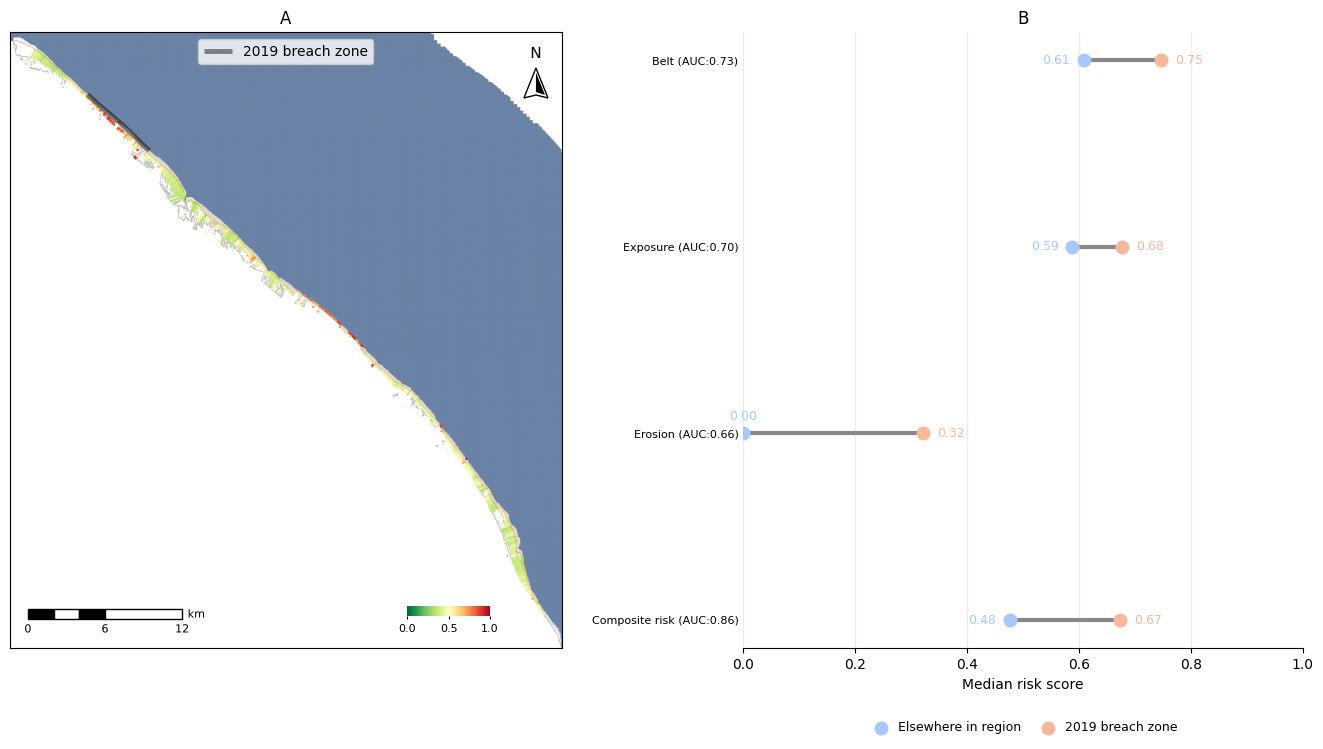

wrote reports/final-report/figures/hindcast_pipeline_fig.png


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_map_utils import north_arrow, scale_bar
from rasterio.plot import plotting_extent

f, c = factors[2018], composed[2018]
risk = c["risk_index"]
pts, norm, Wbelt, mudflat, sea = (f["pts"], f["norm"], f["Wbelt"],
                                  f["mudflat"], f["sea"])
titles = ['A', 'B']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.15, 0.85], "wspace": 0.12})

ext = plotting_extent(mangrove[2018], transform=T)
ax1.imshow(np.ma.masked_where(~mangrove[2018], mangrove[2018]), cmap="Greys", extent=ext)
ax1.imshow(np.ma.masked_where(~sea, sea), cmap="Blues", extent=ext, alpha=.6, vmin=0, vmax=1)

cmap, nrm = plt.cm.RdYlGn_r, plt.Normalize(0, 1)
for i in np.where(f["open_coast"])[0]:
    if not np.isfinite(risk[i]):
        continue
    m0 = mudflat[i] if np.isfinite(mudflat[i]) else 0.0
    a = pts[i] + m0 * norm[i]
    b = pts[i] + (m0 + max(Wbelt[i], risk_config["step_m"])) * norm[i]
    ax1.plot([a[0], b[0]], [a[1], b[1]], color=cmap(nrm(risk[i])), lw=1.4)
    ax1.plot([pts[i][0], a[0]], [pts[i][1], a[1]], color="#74492e", alpha=.25, lw=.8)

north_arrow(
    ax1, location="upper right", scale=0.3,
    fancy=True, shadow=False, label={"position": "top", "text": "N",
                                     "fontfamily": "sans-serif", "fontsize": 11})
scale_bar(ax1, location="lower left", style="boxes",
              bar={"projection": CRS, "unit": "km",
                   "max": 12, "major_div": 2, "minor_div": 3},
              labels={"fontsize": 8, "fontfamily": "sans-serif", "sep": 1, "loc": "below"},
              units={"fontsize": 8, "fontfamily": "sans-serif"})

if breach_mask is not None:
    bp = pts[breach_mask & f["open_coast"]]
    if len(bp):
        ax1.plot(bp[:, 0], bp[:, 1], color="black", lw=3.5, alpha=.45,
                solid_capstyle="butt", label="2019 breach zone")
        ax1.legend(loc="upper center")

sm = plt.cm.ScalarMappable(norm=nrm, cmap=cmap)
cax = ax1.inset_axes([0.72, 0.052, 0.15, 0.016])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, length=2)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title('A')



colors = sns.color_palette("coolwarm", 2)
ax2.set_title('B')

# edge bounds
XLIM, EDGE = (0, 1), 0.07

display_names = {
    "composite": f"Composite risk (AUC:{stats_rows[-1][3]:.2f})",
    "leg_belt": f"Belt (AUC:{stats_rows[0][3]:.2f})",
    "leg_exposure": f"Exposure (AUC:{stats_rows[1][3]:.2f})",
    "leg_erosion": f"Erosion (AUC:{stats_rows[2][3]:.2f})",
}

for yi, (name, med_in, med_out, auc) in enumerate(stats_rows):
    ax2.plot([med_out, med_in], [yi, yi],color='#757575db', lw=3, zorder=1)
    ax2.scatter(med_out, yi,color=colors[0], s=82, zorder=2, label="Elsewhere in region" if yi == 0 else None)
    ax2.scatter(med_in, yi, color=colors[1], s=82, zorder=2,label="2019 breach zone" if yi == 0 else None)

    hi = max(med_out, med_in)
    for x, col in ((med_out, colors[0]), (med_in, colors[1])):
        # space between label and connecting partner (so labels don't collide when points are close)
        out = 1 if x == hi else -1 # which side of the dot? 1 right label or -1 left label
        # crowded areas are dots near the left label near the x axis XLIM=0 or dots near the right label near XLIM=1
        crowded = (x - XLIM[0] < EDGE) if out < 0 else (XLIM[1] - x < EDGE)
        # moving label above dot to prevent colliding with the x axis (left labels) or shifting label left or right
        kw = dict(xytext=(0, 12), ha="center") if crowded else dict(xytext=(10 * out, 0), ha="left" if out > 0 else "right")
        # clip_on False to prevent 0 in erosion label from being clipped by axis boundary
        ax2.annotate(f"{x:.2f}", (x, yi), textcoords="offset points", va="center", fontsize=9, color=col, clip_on=False, **kw)

ax2.set_yticks(range(len(stats_rows)), labels=[display_names[name] for name, *_ in stats_rows])

ax2.set(xlim=XLIM, xlabel="Median risk score", ylabel="")
ax2.tick_params(axis="y", length=0, labelsize=8)
ax2.grid(axis="x", alpha=0.25)
ax2.invert_yaxis()

ax2.legend(
    frameon=False, 
    fontsize=9, 
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    columnspacing=1.1,
    handletextpad=0.4,

)

sns.despine(ax=ax2, left=True)
plt.show()
out = Path("figures/hindcast_pipeline_fig.png")
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"wrote {out.resolve()}")

## Figure 2 
### Table showing the change in risk legs in years leading up to breach event (breached transects vs elsewhere)

In [20]:
EROSION_BASELINE_1YR = {2016: None, 2017: 2016, 2018: 2017} # Controlling erosion interval to 1-year

factors_v2, composed_v2 = {}, {}
for y in YEARS:
    base = EROSION_BASELINE_1YR.get(y)
    prev = mangrove.get(base)
    gap = "" if prev is None else f"  (erosion vs {base}, {y - base}-year gap)"
    print(f"\n{y}" + ("  (base year, no erosion leg)" if prev is None else gap))
    factors_v2[y] = build_factors(
        mangrove[y], water, stack_path(y), T, GRID_CRS,
        prev_mangrove=prev, landcover=landcover[y], population=population, **risk_config)
    composed_v2[y] = compose_index(factors_v2[y], **risk_config)


2016  (base year, no erosion leg)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m

2017  (erosion vs 2016, 1-year gap)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m

2018  (erosion vs 2017, 1-year gap)
water components: 18   ocean = the largest (8,086,999 px)
coastline 67.6 km -> 677 transect origins at 100 m
flipped 2/677 normals to point landward
open-coast transects (fetch >= 1500 m): 604/677 (89%)
median fetch: open 3000 m | excluded 490 m


In [21]:
FACTORS = ["fringe", "evi", "hv", "landcover", "erosion"] # Population doesn't change (estimation from 2020)
rows = [{"factor": n, "year": y, "region": reg, "value": np.nanmean(factors_v2[y][n][m])} 
        for y in YEARS for n in FACTORS for reg, m in (("zone", inb), ("else", outb))]
df = pd.DataFrame(rows)
nested = df.set_index(["factor", "region", "year"])["value"].unstack("year")
nested = nested.reindex(pd.MultiIndex.from_product([FACTORS, ["zone", "else"]], names=["factor", "region"]))
nested['change'] = nested[2018] - nested[2016]
nested

/var/folders/m3/gdh7ygxn66x3pf4x45h809f40000gn/T/ipykernel_4674/3598564713.py:2: RuntimeWarning: Mean of empty slice
  rows = [{"factor": n, "year": y, "region": reg, "value": np.nanmean(factors_v2[y][n][m])}


year                  2016      2017      2018    change
factor    region                                        
fringe    zone    0.843139  0.818458  0.828466 -0.014673
          else    0.652421  0.613627  0.640476 -0.011945
evi       zone    0.822210  0.822274  0.762688 -0.059522
          else    0.519196  0.503914  0.518023 -0.001173
hv        zone    0.499810  0.514832  0.517574  0.017764
          else    0.479792  0.536988  0.498618  0.018826
landcover zone    0.657731  0.616094  0.693890  0.036160
          else    0.426902  0.528432  0.559639  0.132737
erosion   zone         NaN  0.350980  0.361656       NaN
          else         NaN  0.055242  0.047069       NaN

In [35]:
LABELS = {"fringe": "Fringe", "evi": "EVI stress", "hv": "HV weakness",
          "landcover": "Land use", "erosion": "Erosion"}
REGIONS = {"zone": "Breached", "else": "Elsewhere"}
COLS = ["Factor", "Region"] + [str(y) for y in YEARS] + ["Change"]

pretty = (nested.rename(index=LABELS, level="factor")
                .rename(index=REGIONS, level="region"))

tex = pretty.to_latex(multirow=True, float_format="%.3f", na_rep="---")

body = [ln for ln in tex.split(r"\midrule")[1].split(r"\bottomrule")[0].strip().splitlines()
        if not ln.startswith(r"\cline")]

latex = "\n".join([
    r"\begin{table}[htbp]", r"\centering",
    r"\caption{The change in average risk scores for variables in the years (2016-2018) leading up ",
    r"to the 2019 breach in Region Five. Population ",
    "is a static estimate for 2020 and has been excluded. 2016 serves as the base year ", 
    "for shoreline analysis and will not have an erosion score.} ",
    r"\label{tab:hindcast-pipeline-table}",
    r"\begin{adjustbox}{max width=\textwidth}",
    rf"\begin{{tabular}}{{ll{'r' * (len(COLS) - 2)}}}",
    r"\toprule",
    " & ".join(COLS) + r" \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}", r"\end{adjustbox}", r"\end{table}"])

out = Path("tables/hindcast_pipeline_tab.tex")
out.write_text(latex)
print(f"wrote {out.resolve()}\n")
print(latex)

wrote reports/final-report/tables/hindcast_pipeline_tab.tex

\begin{table}[htbp]
\centering
\caption{The change in average risk scores for variables in the years (2016-2018) leading up 
to the 2019 breach in Region Five. Population 
is a static estimate for 2020 and has been excluded. 2016 serves as the base year 
for shoreline analysis and will not have an erosion score.} 
\label{tab:hindcast-pipeline-table}
\begin{adjustbox}{max width=\textwidth}
\begin{tabular}{llrrrr}
\toprule
Factor & Region & 2016 & 2017 & 2018 & Change \\
\midrule
\multirow[t]{2}{*}{Fringe} & Breached & 0.843 & 0.818 & 0.828 & -0.015 \\
 & Elsewhere & 0.652 & 0.614 & 0.640 & -0.012 \\
\multirow[t]{2}{*}{EVI stress} & Breached & 0.822 & 0.822 & 0.763 & -0.060 \\
 & Elsewhere & 0.519 & 0.504 & 0.518 & -0.001 \\
\multirow[t]{2}{*}{HV weakness} & Breached & 0.500 & 0.515 & 0.518 & 0.018 \\
 & Elsewhere & 0.480 & 0.537 & 0.499 & 0.019 \\
\multirow[t]{2}{*}{Land use} & Breached & 0.658 & 0.616 & 0.694 & 0.036 \\
 & El